# Signal Detection Analysis

## Questions
1) Why is the pert start argument in `compute_d_prime` a value of 106? Is it because there were 6 practice trials following 100 trial baseline block? 
2) Is 'SN' consistent across experimental sessions? Confirm.
3) Adding 0.5 to hits and false alarms. Correct method? Citation, description, etc.
4) Are you supposed to exclude "no perturbation" trials from d-prime calculation?
5) For d'=1, do you interpolate on individual level and then average estimates? Or do you interpolate once based on everyone's data?
6) In compute d' function, shouldn't we remove zero deg rotation trials from what is considered 'signal' trials? 

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import numpy.ma as ma
import pandas as pd
import scipy as sp
import seaborn as sns
from scipy import stats
from scipy.stats import bootstrap
from scipy.stats import norm
from scipy.stats import linregress

import statsmodels.api as sm
from statsmodels.formula.api import ols

# # Suppress warnings (temporary)
# warnings.simplefilter(action='ignore', category=FutureWarning)
# warnings.simplefilter(action='ignore', category=DeprecationWarning)

# Set some defaults
# custom_cmap = LinearSegmentedColormap.from_list("custom", ["#F1F744", "#D49BFF"])
sns.set_theme(context="paper", font_scale=1.2)
sns.set_style("ticks")
plt.rcParams["mathtext.default"] = "regular"
plt.rc("axes.spines", top=False, right=False)

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [2]:
df_sdt = pd.read_csv("data/sdt_FINAL.csv")

# change perturbation detection column name to something shorter
df_sdt.rename(columns={'perturbation_responses': 'det'}, inplace=True)

df_sdt.reset_index(drop=True, inplace=True)
df_sdt.columns

Index(['si', 'SN', 'id', 'tester', 'TN', 'move_cycle', 'hX', 'hY', 'rot_hX',
       'rot_hY', 'rotation', 'tgt_jump', 'hand_max_dist', 'radvelmax', 'tgtX',
       'tgtY', 'rot_hand_theta', 'theta_maxradv', 'raw_ep_hand_ang', 'tgt_ang',
       'tgt_dist', 'fbi', 'MT', 'RT', 'ST', 'det'],
      dtype='object')

In [3]:
def remove_outliers(z_thresh: float, df: pd.DataFrame, reach_col: str, subj_col: str):

    """
    Remove outliers from a kinematic variable using within-subject z-scoring.

    Parameters:
    ----------
    z_thresh : float
        The z-score threshold above which data points are considered outliers.
    df : pd.DataFrame
        The input DataFrame containing the kinematic data.
    reach_col : str
        The column name of the kinematic variable to clean (e.g., "theta_maxradv").

    Returns:
    -------
    pd.DataFrame
        The DataFrame with additional columns:
        - <reach_col>_z: z-scored values within each subject (subj_col).
        - <reach_col>_outlier: boolean flag for outliers.
        - <reach_col>_mean: mean of non-outlier trials within each subject.
        - <reach_col>_clean: original values with outliers replaced by NaN.
    """



    # z-score hand angle data
    df[f"{reach_col}_z"] = df.groupby(subj_col)[reach_col].transform(stats.zscore)

    # Create outlier column
    df[f"{reach_col}_outlier"] = np.abs(df[f"{reach_col}_z"]) > z_thresh

    # Calculate within-subject mean using non-outlier trials only
    df[f"{reach_col}_mean"] = df[np.abs(df[f"{reach_col}_z"]) <= z_thresh].groupby(subj_col)[f"{reach_col}"].transform(np.mean)

    # Replace outliers with within-subject mean values
    df[f"{reach_col}_mean"] = df.groupby(subj_col)[f"{reach_col}_mean"].transform(lambda x: x.fillna(np.nanmean(x)))

    ## Create final column with "cleaned" hand angles OR replace outliers with NaNs
    # df["theta_maxradv_clean"] = np.where(np.abs(df["theta_maxradv_z"]) > z_thresh,
    #                                      df["theta_maxradv_mean"],
    #                                      df["theta_maxradv"])
    df[f"{reach_col}_clean"] = np.where(np.abs(df[f"{reach_col}_z"]) > z_thresh,
                                        np.nan,
                                        df[f"{reach_col}"])

    return df


def compute_dp1_linear(df: pd.DataFrame, x_col: str, y_col: str, subj_col: str, s: int):
    
    subj = df[df[subj_col] == s]

    slope, intercept, _, _, _ = linregress(subj[x_col], subj[y_col])
    x_at_y1 = (1 - intercept) / slope

    return slope, intercept, x_at_y1


def compute_d_prime(df: pd.DataFrame, s: int, collapsed: bool, pert_start: int, subj_col: str, rot_col: str, det_col: str):
    
    """
    Compute d' values across rotation conditions for a given subject using signal detection theory.

    Parameters:
        df (pd.DataFrame): The full dataset.
        subj_col (str): Column name for subject IDs.
        rot_col (str): Column name for rotation/perturbation levels.
        s (int): Subject ID to filter on.
        det_col (str): Column name for binary detection responses (1 = detected, 0 = not).

    Returns:
        pd.DataFrame: DataFrame with columns ['SN', 'rotation', 'd prime'].
    """

    # NOTE: Add a 'collapsed' boolean for collapsing rotations. Will be necessary for linear fitting.

    # Select subject s and only select experimental trials
    subj = df[df[subj_col] == s].iloc[pert_start:].copy()

    # Collect rotations and responses
    if collapsed:
        subj[rot_col] = subj[rot_col].abs()

    perts = subj[rot_col].unique()
    # HK adding this next line to remove 0 deg rotations
    perts = perts[perts != 0]
    pert_responses = subj[det_col]

    # Calculate z score for FAs
    noise_trials = len(subj[subj[rot_col] == 0])
    false_alarms = len(subj[(pert_responses == 1) & (subj[rot_col] == 0)])
    false_alarm_rate = (false_alarms + 0.5) / (noise_trials + 1)
    z_false_alarm = norm.ppf(false_alarm_rate)

    # Init df for collecting d prime vals
    # df_sdt = pd.DataFrame(columns=['SN', 'rotation', "d prime"])
    df_sdt = pd.DataFrame()

    # Loops through perts and calculate d prime
    # Concat to df
    for p in perts:
        signal_trials = len(subj[subj[rot_col] == p])
        hits = len(subj[(pert_responses == 1) & (subj[rot_col] == p)])
        hit_rate = (hits + 0.5) / (signal_trials + 1)
        z_hit = norm.ppf(hit_rate)
        d_prime = z_hit - z_false_alarm

        new_row = pd.DataFrame({'SN': [int(s)], 'rotation': [float(p)], 'd prime': [d_prime]})
        df_sdt = pd.concat([df_sdt, new_row], ignore_index=True)
        df_sdt = df_sdt.sort_values(by="rotation").reset_index(drop=True)

    return df_sdt


def compute_dp1_log(df: pd.DataFrame, x_col: str, y_col: str, subj_col: str, s: int):
    
    subj = df[df[subj_col] == s]

    x = subj[x_col].values
    y = subj[y_col].values
    valid = x > 0
    x = x[valid]
    y = y[valid]

    def log_func(x, slope, intercept):
        return slope * np.log(x) + intercept

    params, _ = curve_fit(log_func, x, y)
    slope, intercept = params
    x_at_y1 = np.exp((1 - intercept) / slope)

    return slope, intercept, x_at_y1


def compute_dp1_linear(df: pd.DataFrame, x_col: str, y_col: str, subj_col: str, s: int):
    
    subj = df[df[subj_col] == s]

    slope, intercept, _, _, _ = linregress(subj[x_col], subj[y_col])
    x_at_y1 = (1 - intercept) / slope

    return slope, intercept, x_at_y1


# def plot_dp(df_sdt: pd.DataFrame, s : int, clean_col: str, subj_col: str, rot_col: str, quint_col: str, mean_col: str, dp_col: str):
#     fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4)):
#     # d' plot
#     sns.regplot(data=subj_dp, x=rot_col, y=dp_col, ax=ax3, ci=None, color='r', scatter=False)
#     sns.scatterplot(data=subj_dp, x=rot_col, y=dp_col, ax=ax3, color='grey', alpha=0.5)
#     ax3.axhline(0, ls='--', color='grey', alpha=0.5)

#     # d' = 1 dot
#     ax3.scatter(params[2], y_target, color='w', edgecolor='k', s=75, lw=2, zorder=3)
#     ax3.text(params[2]-1.5, 1.2, f"{params[2]:.3}", fontsize=12, weight='bold')

#     ax3.set_xticks(np.abs(subj_adapt[rot_col]).unique())
#     ax3.set_xlabel(r'Rotation [EGE] ($\degree$)', fontsize=18)
#     ax3.set_ylabel('d\'', fontsize=18)

#     ax3.set_title('c', loc='left', weight='bold', fontsize=20)

#     plt.tight_layout()
#     plt.show()

In [4]:
# Outlier removal
z_thresh = 3.5

# z-score hand angle data
df_sdt["theta_maxradv_z"] = df_sdt.groupby("SN")["theta_maxradv"].transform(stats.zscore)

# z-score movement extent data
df_sdt["hand_max_dist_z"] = df_sdt.groupby("SN")["hand_max_dist"].transform(stats.zscore)

# Create outlier column for hand angle data (classified outlier based on angle and distance)
df_sdt["theta_maxradv_outlier"] = (
    (np.abs(df_sdt["theta_maxradv_z"]) > z_thresh) 
    | (np.abs(df_sdt["hand_max_dist_z"]) > z_thresh) 
)

# Create outlier column for movement extent data (classified outlier based on angle and distance)
df_sdt["hand_max_dist_outlier"] = (
    (np.abs(df_sdt["theta_maxradv_z"]) > z_thresh) 
    | (np.abs(df_sdt["hand_max_dist_z"]) > z_thresh) 
)

# Calculate within-subject mean of hand angle using non-outlier trials only
df_sdt["theta_maxradv_mean"] = (
    df_sdt[(np.abs(df_sdt["theta_maxradv_z"]) <= z_thresh) & (np.abs(df_sdt["hand_max_dist_z"]) <= z_thresh)]
    .groupby("SN")["theta_maxradv"].transform(np.mean)
)

# Calculate within-subject mean of movement extent using non-outlier trials only
df_sdt["hand_max_dist_mean"] = (
    df_sdt[(np.abs(df_sdt["theta_maxradv_z"]) <= z_thresh) & (np.abs(df_sdt["hand_max_dist_z"]) <= z_thresh)]
    .groupby("SN")["hand_max_dist"].transform(np.mean)
)

# Replace outliers with NaNs
df_sdt["theta_maxradv_clean"] = np.where(
    (np.abs(df_sdt["theta_maxradv_z"]) > z_thresh) | (np.abs(df_sdt["hand_max_dist_z"]) > z_thresh),
    np.nan,
    df_sdt["theta_maxradv"])

df_sdt["hand_max_dist_clean"] = np.where(
    (np.abs(df_sdt["theta_maxradv_z"]) > z_thresh) | (np.abs(df_sdt["hand_max_dist_z"]) > z_thresh),
    np.nan,
    df_sdt["hand_max_dist"])

# Create col that replaces outliers with within-subject mean values (may not use)
df_sdt["theta_maxradv_mean"] = df_sdt.groupby("SN")["theta_maxradv_mean"].transform(lambda x: x.fillna(np.nanmean(x)))


/var/folders/42/fy648srd41l966jbjlswhljc0000gr/T/ipykernel_47579/210788385.py:25: FutureWarning: The provided callable <function mean at 0x111d12200> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  .groupby("SN")["theta_maxradv"].transform(np.mean)
/var/folders/42/fy648srd41l966jbjlswhljc0000gr/T/ipykernel_47579/210788385.py:31: FutureWarning: The provided callable <function mean at 0x111d12200> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  .groupby("SN")["hand_max_dist"].transform(np.mean)


In [5]:
# Count number of outliers per participant
num_outliers = df_sdt.groupby("SN")["theta_maxradv_outlier"].sum()
print(num_outliers)

# Print proportion of trials removed
print(num_outliers / df_sdt["TN"].max())

SN
1      2
2      2
3     17
4      3
5      7
6      5
7      6
8      4
9      9
10     5
11    12
12     4
13     6
14     2
15     3
16     6
Name: theta_maxradv_outlier, dtype: int64
SN
1     0.002208
2     0.002208
3     0.018764
4     0.003311
5     0.007726
6     0.005519
7     0.006623
8     0.004415
9     0.009934
10    0.005519
11    0.013245
12    0.004415
13    0.006623
14    0.002208
15    0.003311
16    0.006623
Name: theta_maxradv_outlier, dtype: float64


In [6]:
df_sdt_clean = remove_outliers(3.5, df_sdt, 'theta_maxradv', 'SN')

# Count number of outliers per participant
num_outliers = df_sdt_clean.groupby("SN")["theta_maxradv_outlier"].sum()
print(num_outliers)

# Print proportion of trials removed
print(num_outliers / df_sdt_clean["TN"].max())

SN
1      1
2      2
3     11
4      1
5      4
6      3
7      2
8      3
9      6
10     3
11     6
12     1
13     1
14     2
15     0
16     5
Name: theta_maxradv_outlier, dtype: int64
SN
1     0.001104
2     0.002208
3     0.012141
4     0.001104
5     0.004415
6     0.003311
7     0.002208
8     0.003311
9     0.006623
10    0.003311
11    0.006623
12    0.001104
13    0.001104
14    0.002208
15    0.000000
16    0.005519
Name: theta_maxradv_outlier, dtype: float64


/var/folders/42/fy648srd41l966jbjlswhljc0000gr/T/ipykernel_47579/3943793778.py:34: FutureWarning: The provided callable <function mean at 0x111d12200> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  df[f"{reach_col}_mean"] = df[np.abs(df[f"{reach_col}_z"]) <= z_thresh].groupby(subj_col)[f"{reach_col}"].transform(np.mean)


In [7]:
# Compute baseline motor variability based on last 50 baseline trials 
df_sdt_clean["motor_sd"] = (
    df_sdt_clean[(df_sdt_clean["TN"] >= 51) & (df_sdt_clean["TN"] <= 100)].groupby("SN")["theta_maxradv_clean"].transform(np.nanstd))

# Create col that replaces outliers with within-subject mean values (may not use)
df_sdt_clean["motor_sd"] = df_sdt_clean.groupby("SN")["motor_sd"].transform(lambda x: x.fillna(np.nanmean(x)))

/var/folders/42/fy648srd41l966jbjlswhljc0000gr/T/ipykernel_47579/3974543091.py:3: FutureWarning: The provided callable <function nanstd at 0x112cc0040> is currently using SeriesGroupBy.std. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "std" instead.
  df_sdt_clean[(df_sdt_clean["TN"] >= 51) & (df_sdt_clean["TN"] <= 100)].groupby("SN")["theta_maxradv_clean"].transform(np.nanstd))


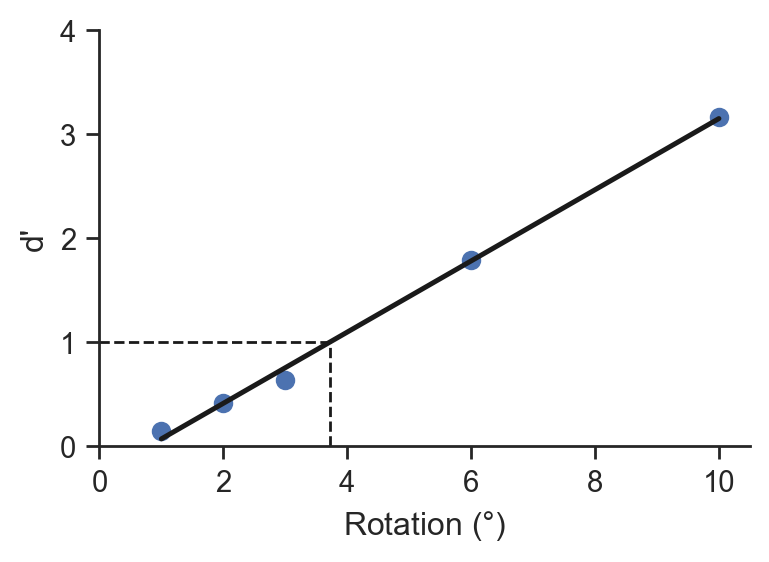

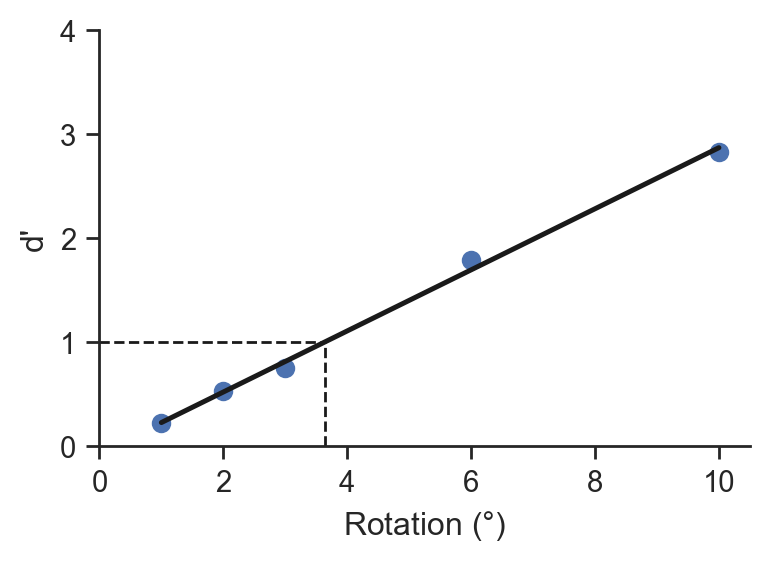

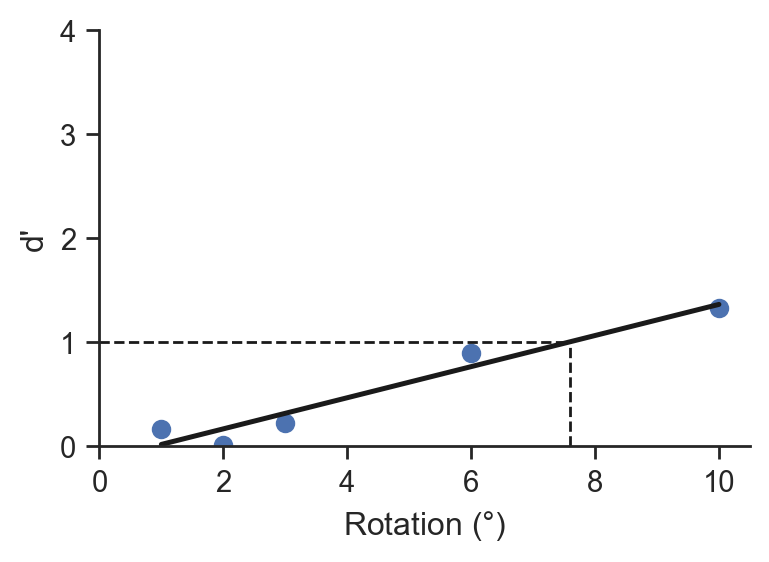

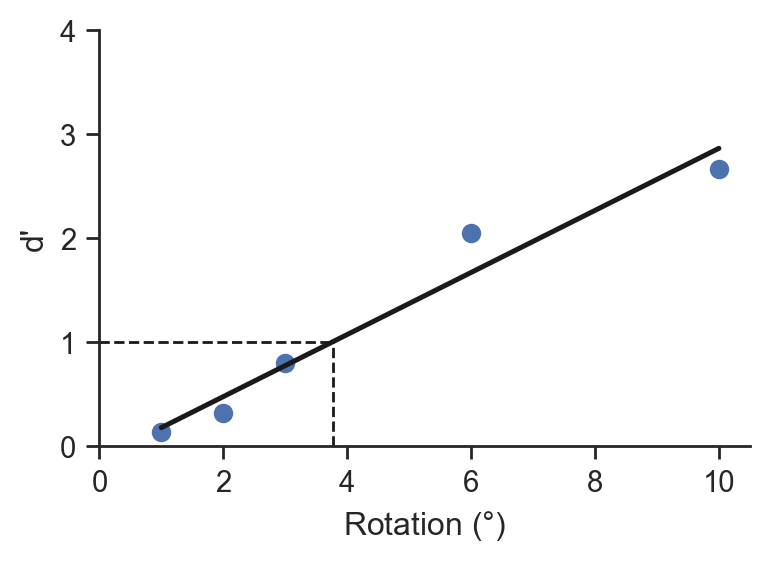

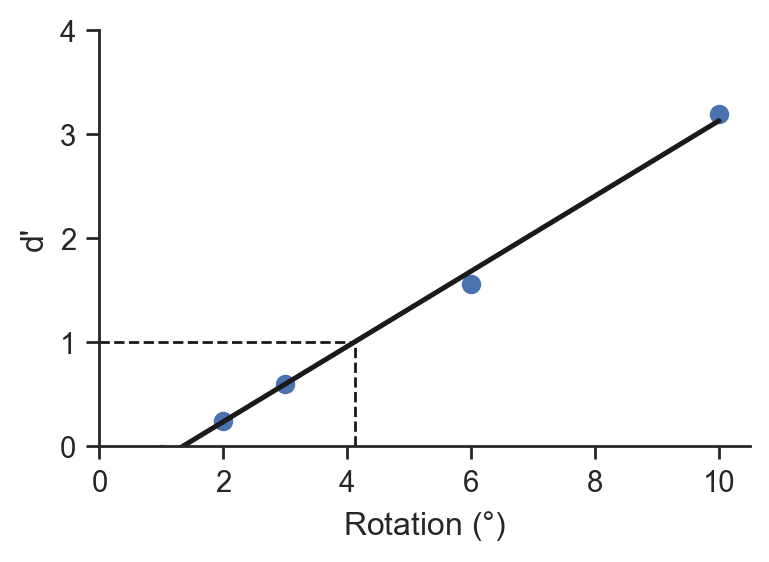

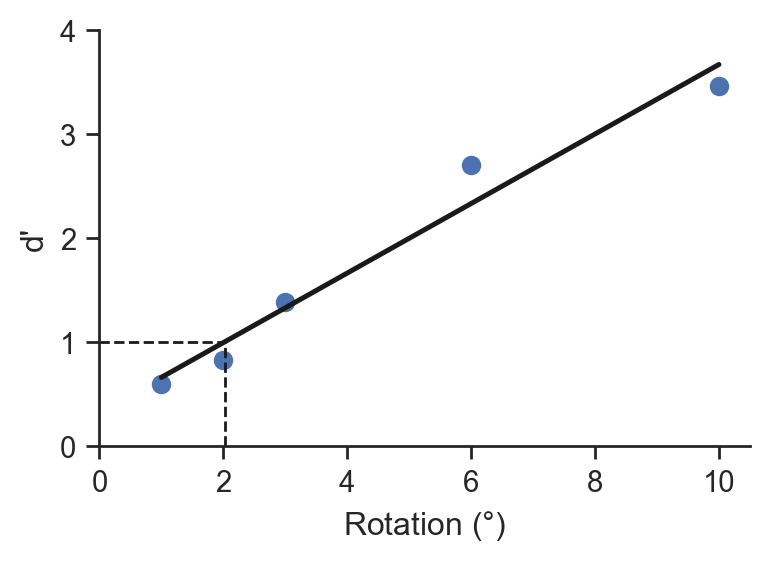

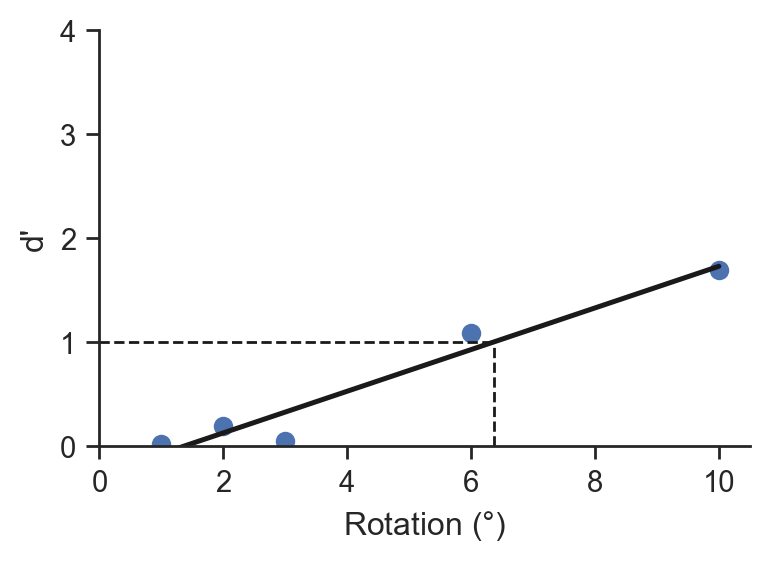

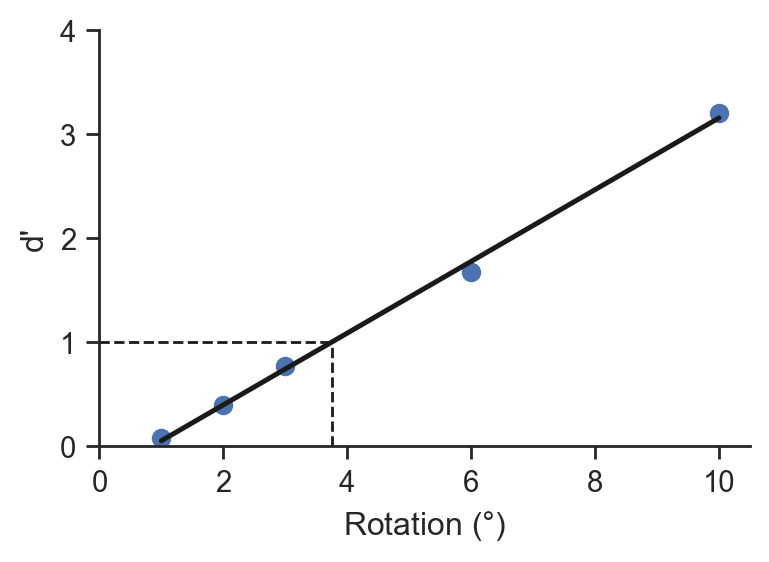

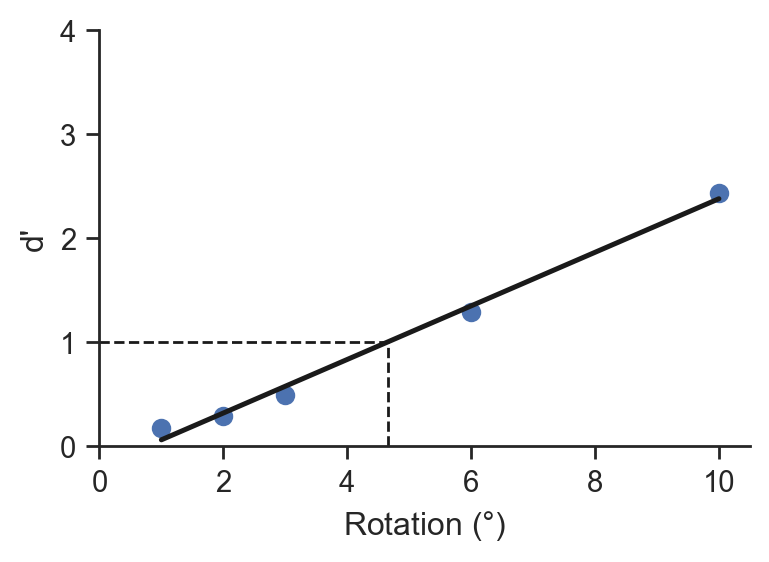

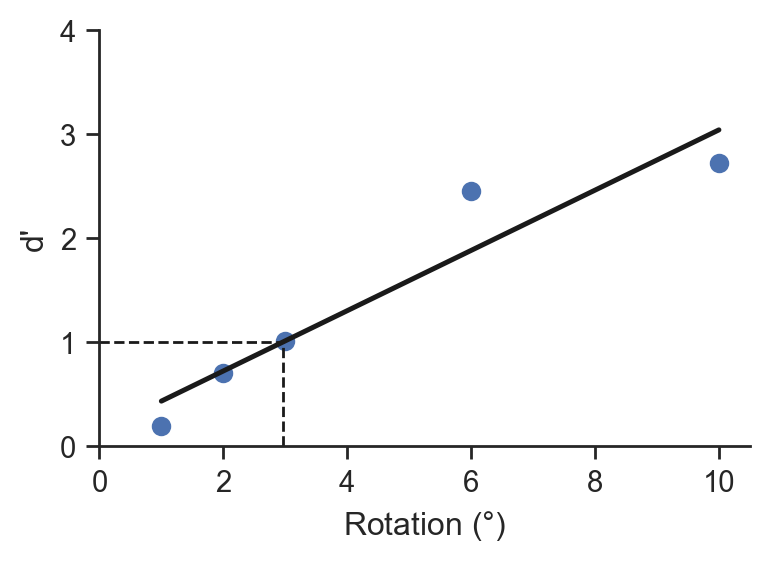

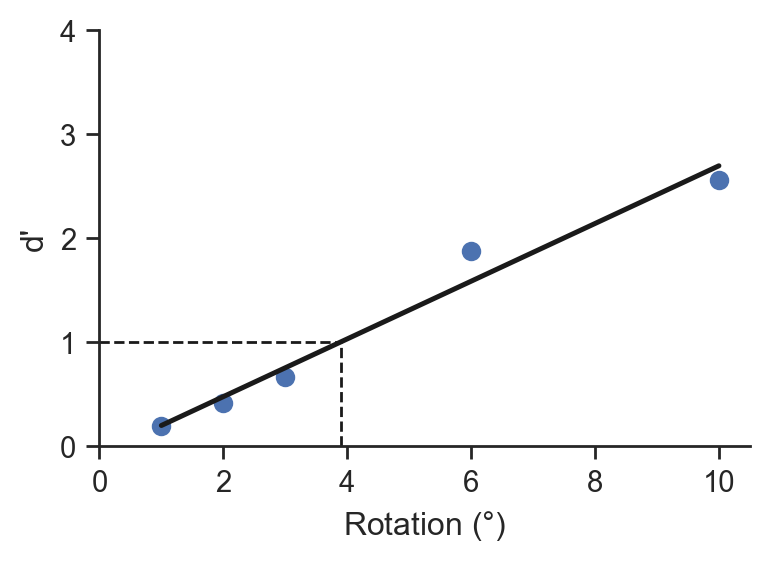

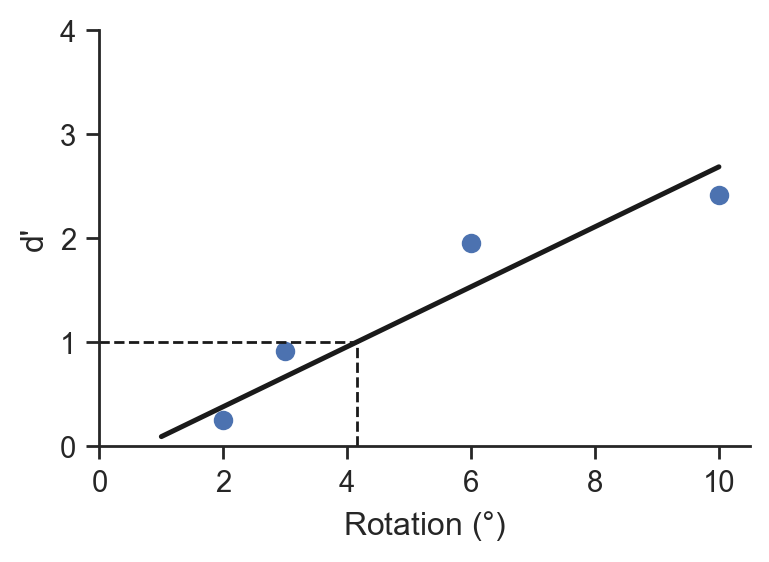

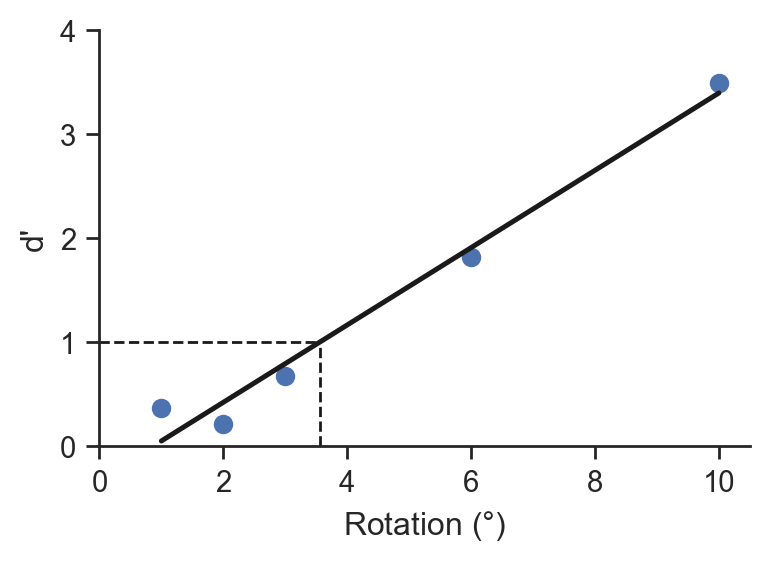

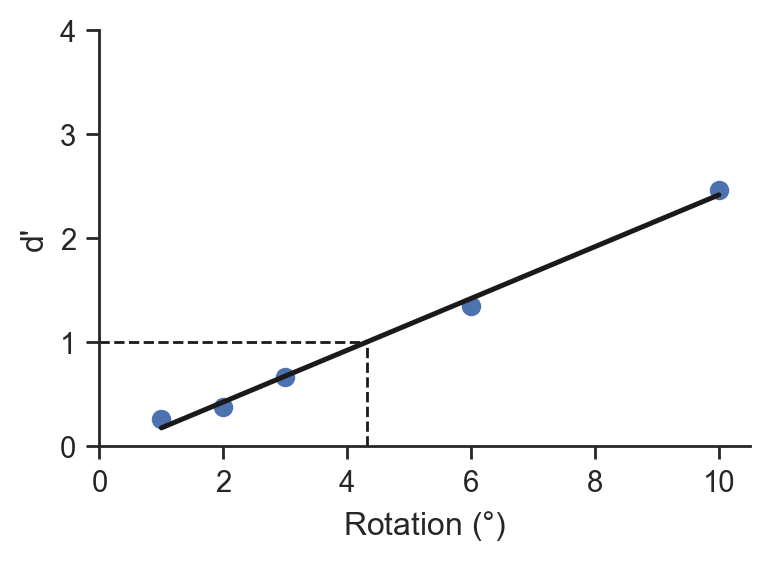

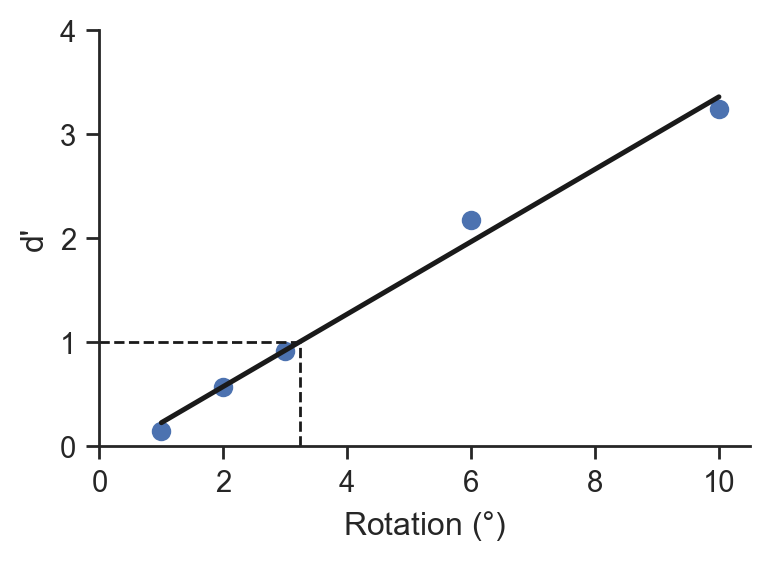

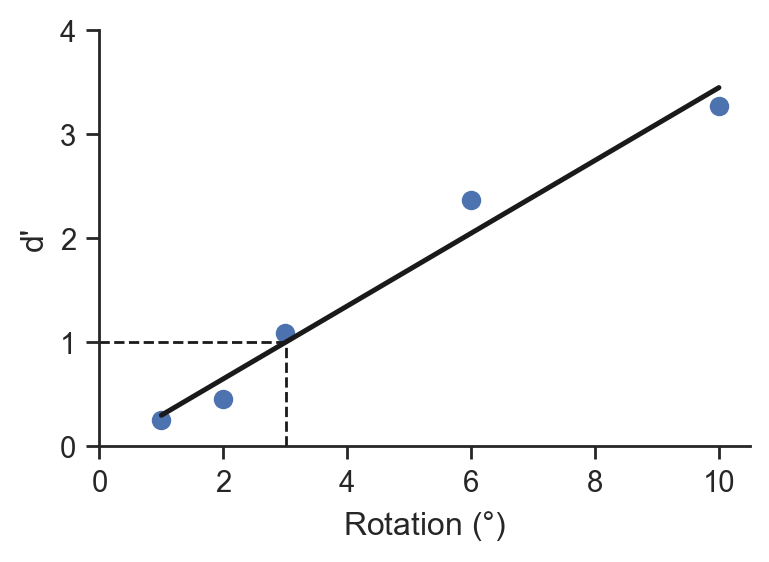

In [46]:
# Plot individual subject data - log vs linear fits
save_fig = True

# Initialize dataframe
dprimes = pd.DataFrame()
dprime_1_ege = np.zeros(len(df_sdt_clean['SN'].unique()))
for k, s in enumerate(df_sdt_clean['SN'].unique()):
    df_dp = compute_d_prime(df_sdt_clean, s, True, 106, "SN", "rotation", "det")
    dprimes = pd.concat([dprimes, df_dp])

    # d' = 1 for linear fit
    slope, intercept, r, p_val, std_err = linregress(df_dp['rotation'], df_dp['d prime'])
    dprime_1_ege[k] = (1 - intercept) / slope
    
    fig, ax = plt.subplots(figsize=(4, 3))
    ax.plot(df_dp["rotation"], df_dp["d prime"], marker="o", markersize=6, linestyle=" ")
    sns.regplot(df_dp, x=df_dp["rotation"], y=df_dp["d prime"], color="k", ci=0, ax=ax)
    ax.set(xlim=[0, 10.5], ylim=[0, 4.0])
    ax.hlines(y=1, xmin=0, xmax=dprime_1_ege[k], color="k", linestyle="--", linewidth=1)
    ax.vlines(x=dprime_1_ege[k], ymin=0, ymax=1, color="k", linestyle="--", linewidth=1)
    ax.set(xlabel="Rotation ($\degree$)", ylabel="d'")
    
    fig.tight_layout()
    
    if (save_fig) & (k == 0):
        fig.savefig("../figs/pert-detect-subj.pdf")
        

In [9]:
dprimes.groupby("rotation")["d prime"].describe()

,count,mean,std,min,25%,50%,75%,max
rotation,,,,,,,,
1.0,16.0,0.165994,0.173942,-0.176672,0.117258,0.167965,0.225568,0.596035
2.0,16.0,0.385078,0.204719,0.006883,0.245718,0.383618,0.474133,0.828616
3.0,16.0,0.725172,0.318136,0.049161,0.623589,0.714409,0.909495,1.381640
6.0,16.0,1.800908,0.494461,0.897279,1.504868,1.806150,2.080918,2.706598
10.0,16.0,2.758925,0.614359,1.322720,2.455251,2.776490,3.215571,3.493086


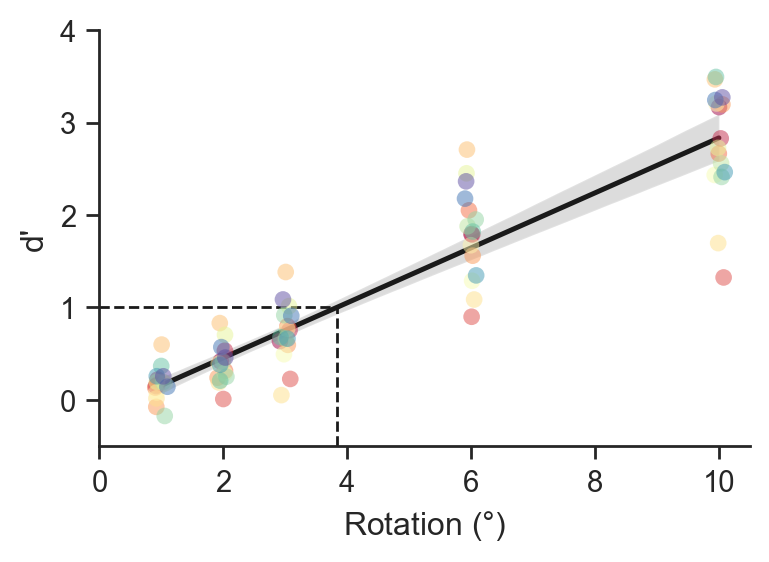

In [47]:
# Interpolate d'=1 for individuals and at group level
slope, intercept, r, p_val, std_err = linregress(dprimes['rotation'], dprimes['d prime'])
interp_dprime = (1 - intercept) / slope

# Plot
fig, ax = plt.subplots(figsize=(4, 3))
sns.regplot(dprimes, x="rotation", y="d prime", color="k", marker="", ax=ax)
sns.stripplot(
    dprimes, x="rotation", y="d prime", hue="SN", palette=sns.color_palette("Spectral", as_cmap=True), 
    alpha=0.5, s=6, native_scale=True, legend=False, ax=ax
)
ax.set(xlim=[0, 10.5], ylim=[-0.5, 4], yticks=np.arange(0, 4.1, 1), xlabel="Rotation ($\degree$)", ylabel="d'")
ax.vlines(x=interp_dprime, ymin=ax.get_ylim()[0], ymax=1, color="k", linestyle="--", linewidth=1)
ax.hlines(y=1, xmin=0, xmax=interp_dprime, color="k", linestyle="--", linewidth=1)
fig.tight_layout()
plt.show()

fig.savefig("../figs/pert-detect-group.pdf")


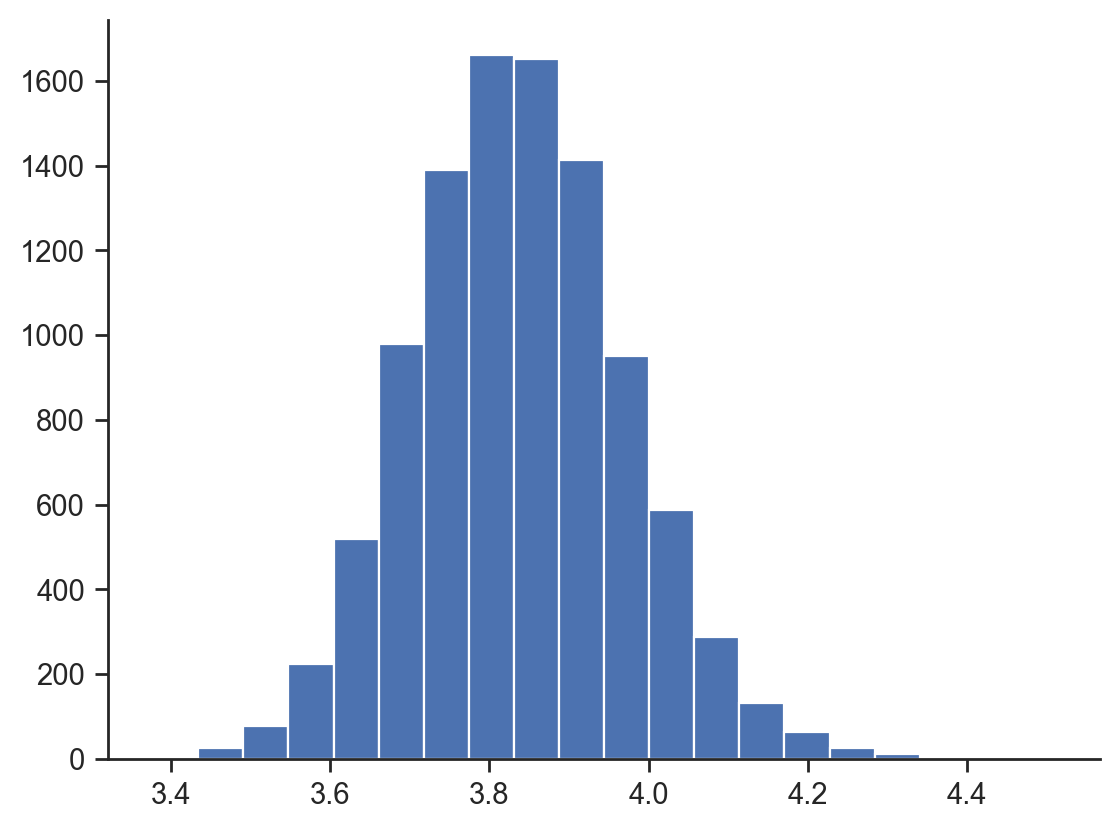

In [11]:
# Create bootstrapped distribution of d' 
dprimes_boot = pd.concat([
    dprimes.sample(frac=1, replace=True).assign(replicate=n)
    for n in range(10000)
])


# Group by replicate and apply linregress
res = dprimes_boot.groupby("replicate").apply(lambda x: linregress(x["rotation"], x["d prime"]))

# Compute interpolated d'=1 on bootstrapped samples (index 0: slope; index 1: intercept)
(1 - intercept) / slope
dprime_1_boot = res.apply(lambda x: (1 - x[1]) / x[0])

# Compute empirical 95% CI
ci_bounds = dprime_1_boot.quantile([0.025, 0.975])

# Plot for sanity check
fig, ax = plt.subplots()
ax.hist(dprime_1_boot, bins=20)
plt.show()


1.7751273348442398 0.12805635706042395 0.6364779970348353


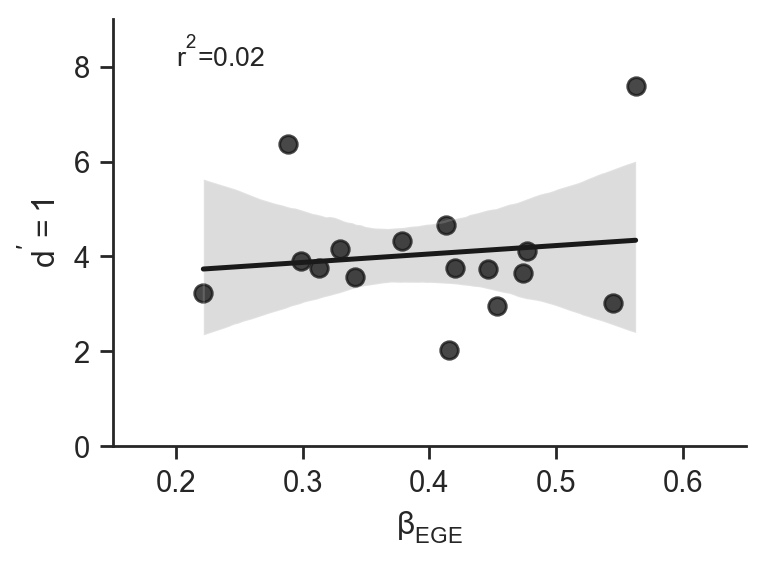

In [57]:
# Comparison of implicit vs explicit EGE sensitivity
df_compare = pd.read_csv("slopes.csv")
df_compare["dprime_interp"] = dprime_1_ege
df_compare["beta_ege_6ege_norm"] = (
    df_compare["beta_ege_6ege_bi"] 
    / (np.abs(df_compare["beta_ege_6ege_bi"]) + np.abs(df_compare["beta_ige_6ege_bi"]))
)

# Compute regression params
slope, intercept, r, p_val, std_err = linregress(df_compare["beta_ege_6ege_uni"], df_compare["dprime_interp"])
r2 = r**2
print(slope, r, p_val)

# Compare implicit adaptation sensitivity (-6:6 deg) to interpolated d'
fig, ax = plt.subplots(figsize=(4,3))
sns.regplot(data=df_compare, x="beta_ege_6ege_uni", y="dprime_interp", color="k", scatter_kws=dict(s=40), ax=ax)
ax.set(xlabel=r"$\beta_{EGE}$", ylabel="$d'=1$", xlim=(0.15, 0.65), ylim=(0, 9))
# Add r2 value to plot
ax.text(0.2, 8, f"$r^2$={r2:.2f}", fontsize="small")
fig.tight_layout()
plt.show()
fig.savefig("../figs/beta-vs-dprime.pdf")




---
## Statistics

In [13]:
# Baseline motor variability
res = bootstrap((df_sdt_clean["motor_sd"].unique(),), np.mean, method="percentile")
print(f"Mean and 95% CI of baseline motor variability: {df_sdt_clean.motor_sd.mean()},{[res.confidence_interval]}")

# Interpolated d'=1 level from individual fits
res = bootstrap((dprime_1_ege,), np.mean, method="percentile")
print(f"Mean and 95% CI of interpolated d' of 1 pert levels: {dprime_1_ege.mean()},{[res.confidence_interval]}")

# Interpolated d'=1 from fitting all individuals at once
print(f"Mean and 95% CI of interpolated d' of 1 pert levels: {dprime_1_boot.mean()},{[ci_bounds.values]}")

Mean and 95% CI of baseline motor variability: 2.0678922705166944,[ConfidenceInterval(low=1.8840000439186981, high=2.2214665673773992)]
Mean and 95% CI of interpolated d' of 1 pert levels: 4.049297518061077,[ConfidenceInterval(low=3.4850356099940965, high=4.717437636391422)]
Mean and 95% CI of interpolated d' of 1 pert levels: 3.838297197178651,[array([3.59010505, 4.10680497])]
